# Method B — HOG + GLCM + RBF-SVM

This is the complete Method B experiment: load the B2 patch dataset, cache HOG+GLCM features, train the SVM, inspect patch classification, generate full-image confidence maps, choose the mask threshold on validation images, then run the test set once.

Core algorithms remain in `src/method_b.py`. This notebook only orchestrates the experiment and presents its results. The test cells must be run only after the validation threshold has been frozen.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'method_b.py').exists(), 'Start Jupyter in the repository or notebooks folder.'
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from src import config, data, evaluate, method_b, utils

utils.set_seed()
B2_DATASET = ROOT.parents[1] / 'Concrete Crack B2 32x32 Center 2x2'
CACHE_DIR = B2_DATASET / '_feature_cache'
MODEL_PATH = config.MODELS_DIR / 'method_b.joblib'
params = utils.load_params('B', method_b.DEFAULT_PARAMS)
split = data.load_split()
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
print('Dataset:', B2_DATASET)
print('Image split:', {name: len(ids) for name, ids in split.items()})
print('Parameters:', params)

Dataset: F:\bowen\UTS-study\sem3\image\Concrete Crack B2 32x32 Center 2x2
Image split: {'train': 320, 'val': 69, 'test': 69}
Parameters: {'patch': 32, 'stride': 16, 'svm_C': 1.0, 'svm_gamma': 'scale', 'threshold': 0.5, 'patches_per_class': 2000}


## 1. Verify and inspect B2

Positive patches come from the fixed image-level split and have a ground-truth `2×2` crack region at their centre. Negative patches are the centre crops retained from B1. Expected totals are 28,000 train, 6,000 validation and 6,000 test patches.

In [2]:
EXPECTED = {'train': 14000, 'val': 3000, 'test': 3000}
dataset_rows = []
for split_name, per_class in EXPECTED.items():
    for class_name in ('Negative', 'Positive'):
        files = sorted((B2_DATASET / split_name / class_name).glob('*.png'))
        assert len(files) == per_class, (split_name, class_name, len(files))
        sample = utils.read_image(files[0])
        assert sample.shape == (32, 32, 3)
        dataset_rows.append({'split': split_name, 'class': class_name, 'patches': len(files)})
pd.DataFrame(dataset_rows)

,split,class,patches
0,train,Negative,14000
1,train,Positive,14000
2,val,Negative,3000
3,val,Positive,3000
4,test,Negative,3000
5,test,Positive,3000


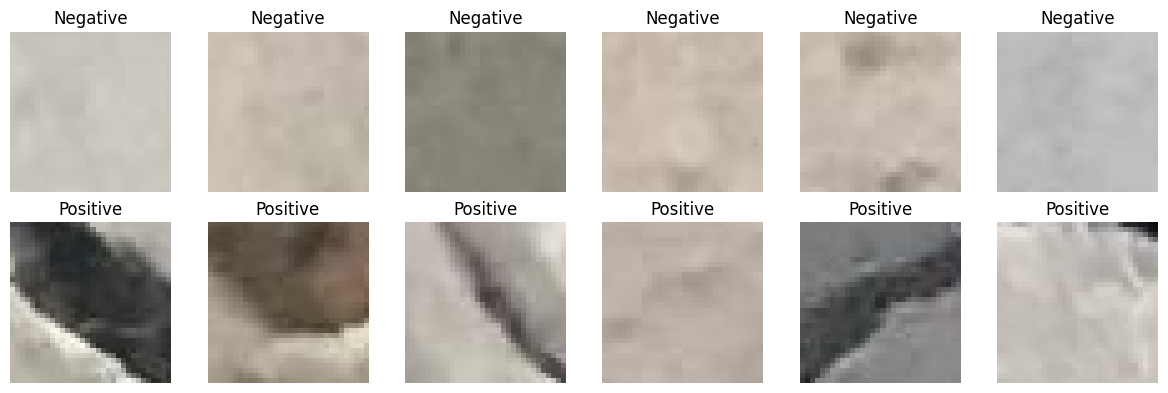

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for row, class_name in enumerate(('Negative', 'Positive')):
    files = sorted((B2_DATASET / 'train' / class_name).glob('*.png'))
    indices = np.random.default_rng(config.SEED + row).choice(len(files), 6, replace=False)
    for axis, index in zip(axes[row], indices):
        axis.imshow(utils.read_image(files[index]))
        axis.set_title(class_name)
        axis.axis('off')
plt.tight_layout()

## 2. Extract HOG + GLCM features

Feature arrays are cached beside the generated B2 dataset. Delete `_feature_cache` only when the feature definition changes.

In [4]:
LABELS = {'Negative': 0, 'Positive': 1}

def load_feature_split(split_name):
    cache_path = CACHE_DIR / f'hog_glcm_v1_{split_name}.npz'
    if cache_path.exists():
        cached = np.load(cache_path)
        print('Loaded', cache_path)
        return cached['features'], cached['labels']

    items = [(path, label)
             for class_name, label in LABELS.items()
             for path in sorted((B2_DATASET / split_name / class_name).glob('*.png'))]
    features = np.empty((len(items), 340), dtype=np.float32)
    labels = np.empty(len(items), dtype=np.uint8)
    for index, (path, label) in enumerate(items):
        features[index] = method_b.extract_features_b(utils.read_image(path))
        labels[index] = label
        if (index + 1) % 2000 == 0:
            print(f'{split_name}: {index + 1:,}/{len(items):,}')
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache_path, features=features, labels=labels)
    return features, labels

X_train, y_train = load_feature_split('train')
X_val, y_val = load_feature_split('val')
print('Train:', X_train.shape, np.bincount(y_train))
print('Validation:', X_val.shape, np.bincount(y_val))

Loaded F:\bowen\UTS-study\sem3\image\Concrete Crack B2 32x32 Center 2x2\_feature_cache\hog_glcm_v1_train.npz
Loaded F:\bowen\UTS-study\sem3\image\Concrete Crack B2 32x32 Center 2x2\_feature_cache\hog_glcm_v1_val.npz
Train: (28000, 340) [14000 14000]
Validation: (6000, 340) [3000 3000]


## 3. Train the classifier

The fitted pipeline standardises the 340 HOG+GLCM features and trains the configured RBF-SVM. With 28,000 training patches this can take time.

In [5]:
with utils.timer() as training_time:
    model = method_b.fit_classifier_b(X_train, y_train, params)
method_b.save_model_b(model, MODEL_PATH)
print(f'Trained in {training_time["seconds"]:.1f} s')
print('Saved:', MODEL_PATH)

Trained in 362.5 s
Saved: F:\bowen\UTS-study\sem3\image\Github\crack-width-measurement\models\method_b.joblib


              precision    recall  f1-score   support

    Negative     0.9298    0.9763    0.9525      3000
    Positive     0.9751    0.9263    0.9501      3000

    accuracy                         0.9513      6000
   macro avg     0.9525    0.9513    0.9513      6000
weighted avg     0.9525    0.9513    0.9513      6000



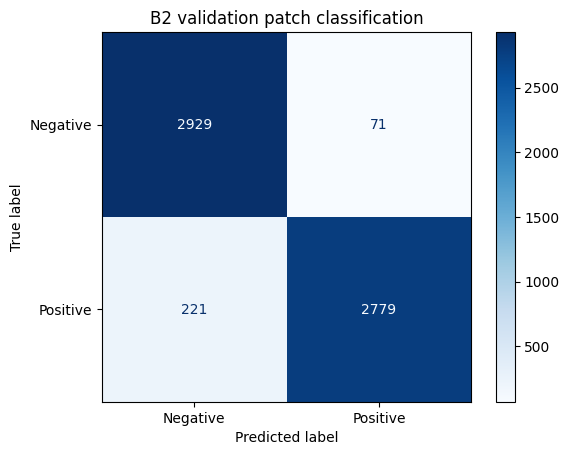

In [6]:
val_patch_prediction = model.predict(X_val)
print(classification_report(y_val, val_patch_prediction, target_names=['Negative', 'Positive'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, val_patch_prediction, display_labels=['Negative', 'Positive'], cmap='Blues')
plt.title('B2 validation patch classification')
plt.show()

## 4. Validation confidence maps and threshold selection

Each full validation image is scanned once. Overlapping patch probabilities are aggregated by `method_b.segment_b` into an image-sized confidence map and saved under `results/B/val`. Thresholds are compared using strict pixel-level Precision, Recall, Dice/F1 and IoU. This is the slowest stage.

In [7]:
def strict_counts(prediction, reference):
    return (
        int(np.count_nonzero(prediction & reference)),
        int(np.count_nonzero(prediction & ~reference)),
        int(np.count_nonzero(~prediction & reference)),
    )

def metrics_from_triplet(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        'precision': precision,
        'recall': recall,
        'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0,
        'iou': tp / (tp + fp + fn) if tp + fp + fn else 1.0,
    }

def validation_threshold_table():
    totals = {float(t): [0, 0, 0] for t in THRESHOLDS}
    for index, image_id in enumerate(split['val'], start=1):
        image, reference = data.load_pair(image_id)
        _, confidence = method_b.segment_b(image, model, params)
        utils.save_prob(confidence, utils.result_path('B', 'val', image_id, 'prob'))
        for threshold in THRESHOLDS:
            counts = strict_counts(confidence >= threshold, reference)
            totals[float(threshold)] = [a + b for a, b in zip(totals[float(threshold)], counts)]
        print(f'validation {index}/{len(split["val"])}: {image_id}')
    return pd.DataFrame([{'threshold': threshold, **metrics_from_triplet(*counts)}
                         for threshold, counts in totals.items()])

validation_thresholds = validation_threshold_table()
validation_thresholds

validation 1/69: 040
validation 2/69: 046
validation 3/69: 051
validation 4/69: 053
validation 5/69: 054
validation 6/69: 071
validation 7/69: 095
validation 8/69: 106
validation 9/69: 111
validation 10/69: 122
validation 11/69: 131
validation 12/69: 132
validation 13/69: 140
validation 14/69: 141
validation 15/69: 150
validation 16/69: 175
validation 17/69: 177
validation 18/69: 178
validation 19/69: 179
validation 20/69: 189
validation 21/69: 204
validation 22/69: 211
validation 23/69: 227
validation 24/69: 232
validation 25/69: 235
validation 26/69: 248
validation 27/69: 250
validation 28/69: 251
validation 29/69: 265
validation 30/69: 278
validation 31/69: 281
validation 32/69: 283
validation 33/69: 324
validation 34/69: 374
validation 35/69: 376
validation 36/69: 403
validation 37/69: 408
validation 38/69: 418
validation 39/69: 419
validation 40/69: 433
validation 41/69: 451
validation 42/69: 455
validation 43/69: 457
validation 44/69: 463
validation 45/69: 466
validation 46/69: 4

,threshold,precision,recall,f1,iou
0,0.10,0.043948,0.978518,0.084118,0.043906
1,0.15,0.063880,0.971929,0.119882,0.063763
2,0.20,0.085761,0.965833,0.157533,0.085501
3,0.25,0.109439,0.960522,0.196490,0.108949
4,0.30,0.134551,0.954771,0.235863,0.133699
5,0.35,0.161065,0.949213,0.275399,0.159688
6,0.40,0.189360,0.943609,0.315423,0.187241
7,0.45,0.219824,0.936825,0.356091,0.216613
8,0.50,0.255843,0.927233,0.401033,0.250807
9,0.55,0.297498,0.912299,0.448682,0.289226


Frozen validation-selected threshold: 0.9


,threshold,precision,recall,f1,iou
validation,0.9,0.685253,0.68557,0.685412,0.521389


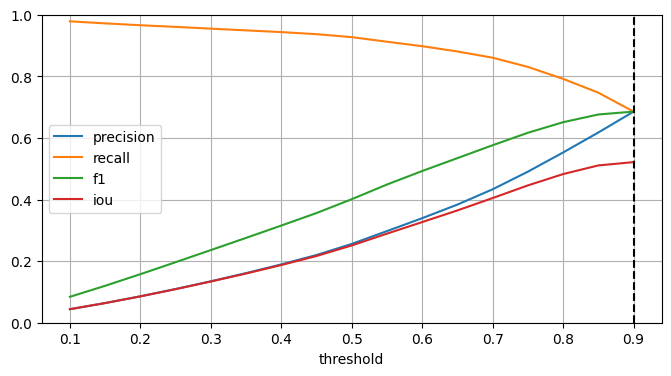

In [8]:
best = validation_thresholds.loc[validation_thresholds['f1'].idxmax()]
params['threshold'] = float(best['threshold'])
utils.save_params('B', params)
config.EVAL_DIR.mkdir(parents=True, exist_ok=True)
validation_thresholds.to_csv(config.EVAL_DIR / 'method_b_validation_thresholds.csv', index=False)

for image_id in split['val']:
    confidence = utils.read_prob(utils.result_path('B', 'val', image_id, 'prob'))
    utils.save_mask(confidence >= params['threshold'], utils.result_path('B', 'val', image_id))

print('Frozen validation-selected threshold:', params['threshold'])
display(best.to_frame('validation').T)
validation_thresholds.plot(x='threshold', y=['precision', 'recall', 'f1', 'iou'], ylim=(0, 1), grid=True, figsize=(8, 4))
plt.axvline(params['threshold'], color='black', linestyle='--')
plt.show()

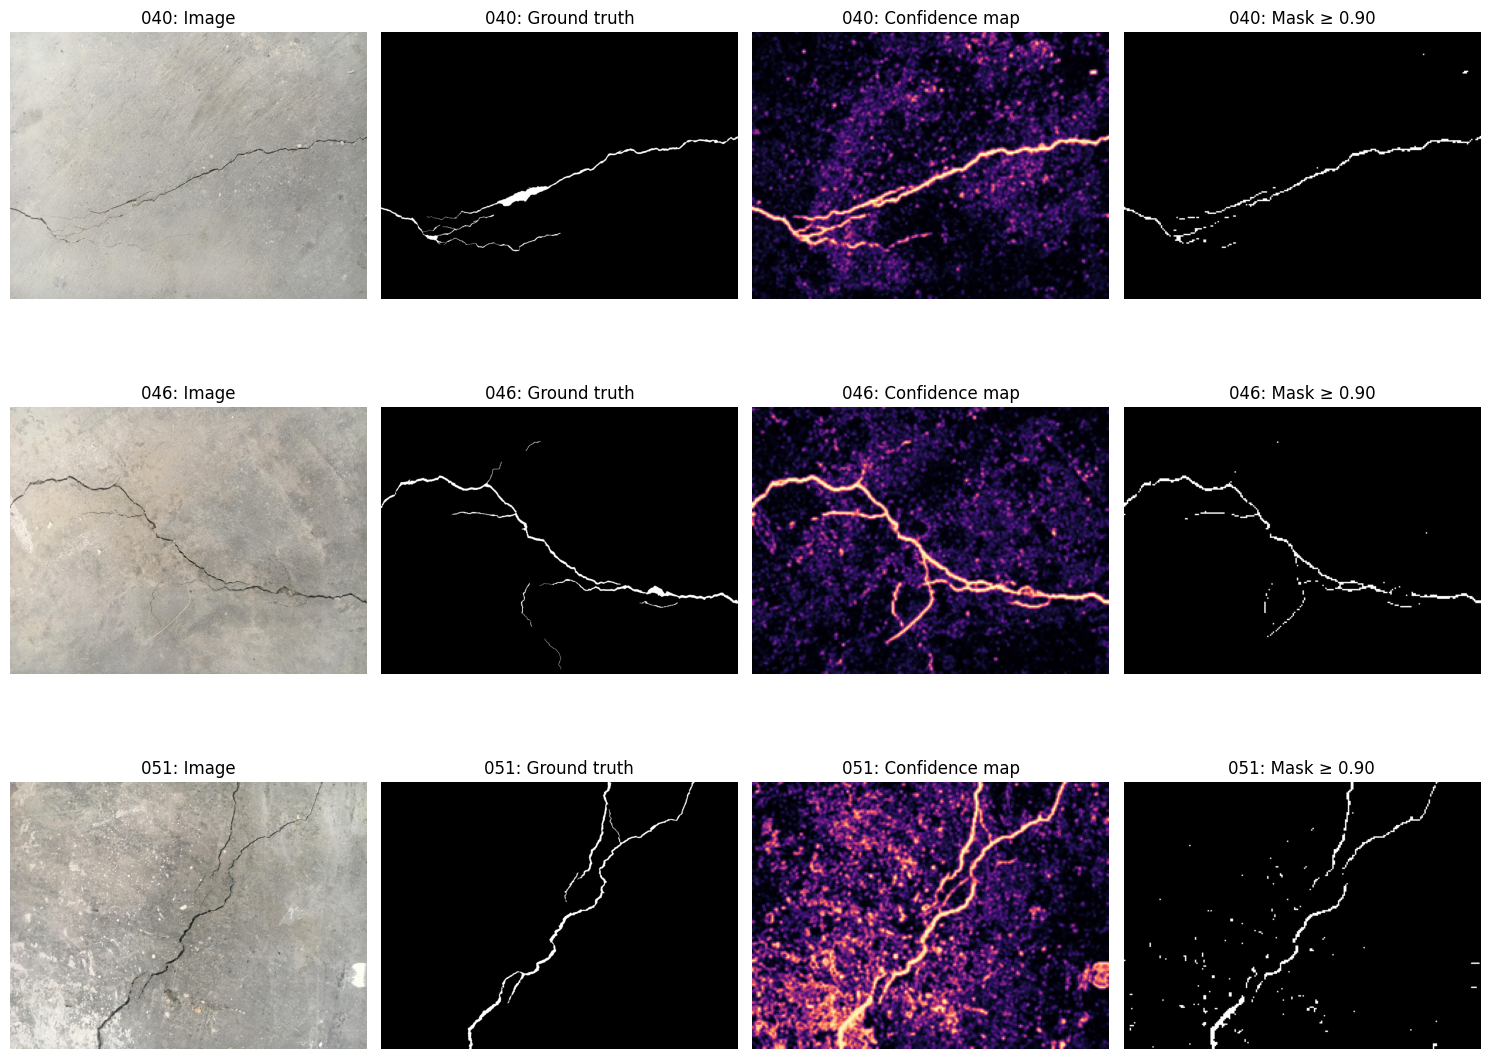

In [9]:
example_ids = split['val'][:3]
fig, axes = plt.subplots(len(example_ids), 4, figsize=(15, 4 * len(example_ids)))
for row, image_id in enumerate(example_ids):
    image, reference = data.load_pair(image_id)
    confidence = utils.read_prob(utils.result_path('B', 'val', image_id, 'prob'))
    prediction = confidence >= params['threshold']
    for axis, value, title, cmap in zip(
        axes[row],
        (image, reference, confidence, prediction),
        ('Image', 'Ground truth', 'Confidence map', f'Mask ≥ {params["threshold"]:.2f}'),
        (None, 'gray', 'magma', 'gray')):
        axis.imshow(value, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axis.set_title(f'{image_id}: {title}')
        axis.axis('off')
plt.tight_layout()

## 5. Final test run

Run the remaining cells only after the model settings and validation-selected threshold are frozen. Test data must not be used for further tuning.

test: 2,000/6,000
test: 4,000/6,000
test: 6,000/6,000
              precision    recall  f1-score   support

    Negative     0.9206    0.9740    0.9466      3000
    Positive     0.9724    0.9160    0.9434      3000

    accuracy                         0.9450      6000
   macro avg     0.9465    0.9450    0.9450      6000
weighted avg     0.9465    0.9450    0.9450      6000



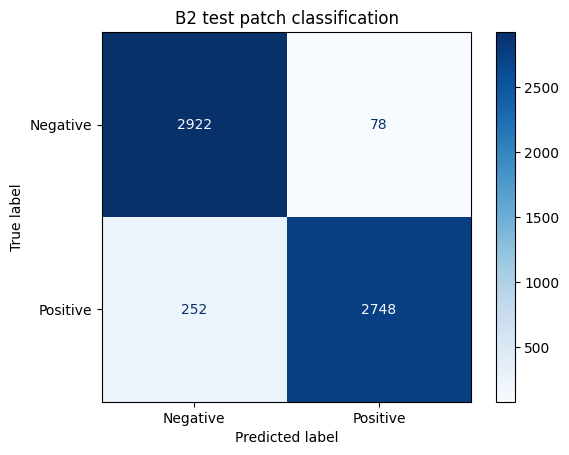

In [10]:
X_test, y_test = load_feature_split('test')
test_patch_prediction = model.predict(X_test)
print(classification_report(y_test, test_patch_prediction, target_names=['Negative', 'Positive'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, test_patch_prediction, display_labels=['Negative', 'Positive'], cmap='Blues')
plt.title('B2 test patch classification')
plt.show()

In [11]:
total_counts = {key: 0 for key in evaluate.COUNT_KEYS}
per_image_rows = []
for index, image_id in enumerate(split['test'], start=1):
    image, reference = data.load_pair(image_id)
    prediction, confidence = method_b.segment_b(image, model, params)
    utils.save_prob(confidence, utils.result_path('B', 'test', image_id, 'prob'))
    utils.save_mask(prediction, utils.result_path('B', 'test', image_id))
    metrics = evaluate.seg_metrics(prediction, reference)
    per_image_rows.append({'image_id': image_id, **metrics})
    for key in evaluate.COUNT_KEYS:
        total_counts[key] += metrics[key]
    print(f'test {index}/{len(split["test"])}: {image_id}')

test_summary = evaluate.metrics_from_counts(total_counts)
test_rows = pd.DataFrame(per_image_rows)
test_rows.to_csv(config.EVAL_DIR / 'method_b_test_per_image.csv', index=False)
pd.DataFrame([test_summary], index=['Method B test'])

test 1/69: 018
test 2/69: 028
test 3/69: 029
test 4/69: 031
test 5/69: 032
test 6/69: 039
test 7/69: 059
test 8/69: 063
test 9/69: 067
test 10/69: 069
test 11/69: 072
test 12/69: 078
test 13/69: 084
test 14/69: 093
test 15/69: 102
test 16/69: 104
test 17/69: 125
test 18/69: 134
test 19/69: 135
test 20/69: 136
test 21/69: 138
test 22/69: 143
test 23/69: 149
test 24/69: 176
test 25/69: 181
test 26/69: 183
test 27/69: 191
test 28/69: 217
test 29/69: 219
test 30/69: 221
test 31/69: 229
test 32/69: 231
test 33/69: 239
test 34/69: 240
test 35/69: 260
test 36/69: 262
test 37/69: 275
test 38/69: 282
test 39/69: 358
test 40/69: 375
test 41/69: 381
test 42/69: 384
test 43/69: 405
test 44/69: 415
test 45/69: 421
test 46/69: 423
test 47/69: 429
test 48/69: 430
test 49/69: 439
test 50/69: 446
test 51/69: 453
test 52/69: 458
test 53/69: 477
test 54/69: 490
test 55/69: 493
test 56/69: 503
test 57/69: 511
test 58/69: 515
test 59/69: 517
test 60/69: 528
test 61/69: 530
test 62/69: 556
test 63/69: 559
t

,precision,recall,f1,iou,tol_precision,tol_recall,tol_f1
Method B test,0.687289,0.675876,0.681535,0.516915,0.754498,0.734503,0.744367


## Interpretation notes

The confidence map has full image dimensions, but it is produced by aggregating overlapping patch probabilities rather than by an independent classifier at every pixel. The B2 positive labels have an exact central `2×2` crack core; the reused B1 negatives retain patch-level provenance. Report patch-classification and full-image segmentation results separately.